# 文献 [23] 含体力方板：传统位移型 PINN

Haghighat E, Raissi M, Moure A, et al. CMAME, 2021, 379:113741. DOI:10.1016/j.cma.2021.113741.

本文件实现用于对比的传统位移型 PINN，不复现文献的多网络参数反演架构。
问题与前一份 KM-PIKFNN 完全相同：单位方板、平面应变、无量纲 $\lambda_{\mathrm L}=1,\mu=0.5,Q=4$。
$$u_x^{exact}=\cos(2\pi x)\sin(\pi y),\qquad u_y^{exact}=(Q/4)\sin(\pi x)y^4.$$
采用同一空间变化体力及混合边界条件。默认物理尺度也相同：$L=1$ m、$E=10^6$ Pa、$\nu=1/3$、$U_{ref}=10^{-4}$ m、$\Sigma_{ref}=75$ Pa。

网络输入坐标、输出位移，通过自动微分求应力和平衡残差：
$$r_x=\partial_x\sigma_{xx}+\partial_y\sigma_{xy}+f_x,\qquad r_y=\partial_x\sigma_{xy}+\partial_y\sigma_{yy}+f_y.$$
$$L_r=\frac1{N_r}\sum_i\frac{r_x^2+r_y^2}{[(\lambda_{\mathrm L}+2\mu)(2\pi)^2]^2},\qquad L=L_r+\sum_{edge}L_{edge}.$$
每个边界损失为该边指定的两个残差的平方和均值。位移与应力使用各自物理尺度无量纲化，和 KM 文件一致；平衡残差另除固定尺度，记录在配置与输出中。

下边：$u_x=u_y=0$；上边：$u_x=0,\sigma_{yy}=(\lambda_{\mathrm L}+2\mu)Q\sin(\pi x)$；左右：$u_y=0,\sigma_{xx}=0$。没有额外的零剪应力条件。

默认 4 个隐藏层、每层 48 个 tanh 神经元；2048 个内部点、400 个边界点；float64；随机初始化；Adam 3000 步＋L-BFGS 100 次外层调用，每次最多 20 次内部迭代。可在 cfg 中提高迭代数。解析解仅用于误差报告，不进入损失、初始化或最佳模型选择。无特解、无基本解核、无暖启动。

输出解析解五张与 PINN 五张云图，损失/误差曲线，CSV、NPZ、网络权重和完整设置。色标平端且与云图等高。与 KM 的评价网格均为 101×101。设置 `km_output_dir` 后可自动读取 KM 数据，输出同网格误差对比表。跨方法组图应使用两方法及解析解的统一范围。

时间包括模型初始化、训练和训练诊断，不包括最后的全场误差计算、绘图及保存。比较应使用同一设备、精度，并明确 KM 的 SVD 暖启动和源点多初值试验耗时，不能只比较优化器步数。单次运行不是随机初始化统计结论。


In [ ]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from pathlib import Path
import time,csv,json

cfg=dict(L=1.0,E_real=1.0e6,nu=1/3,U_ref=1.0e-4,
         seed=42,device='auto',cuda_fallback_to_cpu=True,
         hidden_width=48,hidden_layers=4,n_interior=2048,n_boundary_per_side=100,
         adam_steps=3000,adam_lr=1e-3,lbfgs_epochs=100,lbfgs_max_iter=20,
         log_adam_every=100,log_lbfgs_every=5,weight_pde=1.0,weight_boundary=1.0,
         nx_plot=101,save_outputs=True,output_dir='literature23_pinn_results',
         km_output_dir='literature23_body_force_results')
dtype=torch.float64
torch.manual_seed(cfg['seed']);np.random.seed(cfg['seed'])
def choose_device():
    d=torch.device(('cuda' if torch.cuda.is_available() else 'cpu') if cfg['device']=='auto' else cfg['device'])
    if d.type=='cuda':
        try:
            x=torch.linspace(0.1,0.9,32,device=d,dtype=dtype,requires_grad=True)
            q=torch.tanh(x).square().sum()
            g=torch.autograd.grad(q,x,create_graph=True)[0]
            torch.autograd.grad(g.sum(),x)[0];torch.cuda.synchronize(d)
        except (RuntimeError,OSError,AssertionError) as e:
            if not cfg['cuda_fallback_to_cpu']:raise
            print('CUDA check failed; switching to CPU:',str(e).splitlines()[-1]);d=torch.device('cpu')
    return d
device=choose_device()
if device.type=='cpu':torch.set_num_threads(min(4,torch.get_num_threads()))
L,E_real,nu,U_ref=(cfg[k] for k in ('L','E_real','nu','U_ref'))
if not np.isclose(nu,1/3):raise ValueError('Use nu=1/3 to reproduce literature [23].')
lam,mu,Q=1.0,0.5,4.0
Sigma_ref=E_real*U_ref/((4/3)*L);F_ref=Sigma_ref/L
# Nondimensional momentum residual scale, separate from displacement/stress scales.
# Kept fixed throughout training and saved with all settings.
pde_scale=(lam+2*mu)*(2*np.pi)**2
def tensor(a):return torch.as_tensor(a,dtype=dtype,device=device)
print('Device:',device,'| float64 | displacement PINN | lambda*=1, mu*=0.5, Q=4')
print('Boundary points:',4*cfg['n_boundary_per_side'],'| interior points:',cfg['n_interior'])


Device: cpu | float64 | displacement PINN | lambda*=1, mu*=0.5, Q=4
Boundary points: 400 | interior points: 2048


## 网络、自动微分与 Adam＋L-BFGS 训练


In [ ]:
def exact_fields(z):
    # Reference fields from the published displacement solution.
    x, y = z.real, z.imag
    px, py = torch.pi*x, torch.pi*y
    ux = torch.cos(2*px)*torch.sin(py)
    uy = (Q/4)*torch.sin(px)*y**4
    ex = -2*torch.pi*torch.sin(2*px)*torch.sin(py)
    ey = Q*torch.sin(px)*y**3
    shear = torch.pi*torch.cos(2*px)*torch.cos(py)+(Q*torch.pi/4)*torch.cos(px)*y**4
    return torch.stack((ux,uy,(lam+2*mu)*ex+lam*ey,
                        lam*ex+(lam+2*mu)*ey,mu*shear),dim=-1)

def body_force_fields(z):
    # Sign convention: div(sigma)+f=0. Literature formula, not a fitted force.
    x, y = z.real, z.imag
    px, py = torch.pi*x, torch.pi*y
    fx = ((4*lam+9*mu)*torch.pi**2*torch.cos(2*px)*torch.sin(py)
          -(lam+mu)*torch.pi*Q*y**3*torch.cos(px))
    fy = (2*(lam+mu)*torch.pi**2*torch.sin(2*px)*torch.cos(py)
          -3*(lam+2*mu)*Q*y**2*torch.sin(px)
          +(mu*torch.pi**2*Q/4)*y**4*torch.sin(px))
    return torch.stack((fx,fy),dim=-1)

def boundary_columns(key):
    # bottom: ux,uy; top: ux,syy; sides: uy,sxx. No extra shear condition.
    return {'bottom':(0,1),'top':(0,3),'left':(1,2),'right':(1,2)}[key]

def prescribed_boundary(key,z):
    out = torch.zeros((len(z),2),dtype=dtype,device=device)
    if key == 'top':
        out[:,1] = (lam+2*mu)*Q*torch.sin(torch.pi*z.real)
    return out


class DisplacementPINN(nn.Module):
    def __init__(self):
        super().__init__()
        sizes=[2]+[cfg['hidden_width']]*cfg['hidden_layers']+[2]
        modules=[]
        for i,(a,b) in enumerate(zip(sizes[:-1],sizes[1:])):
            layer=nn.Linear(a,b,dtype=dtype)
            nn.init.xavier_normal_(layer.weight);nn.init.zeros_(layer.bias)
            modules.append(layer)
            if i<len(sizes)-2:modules.append(nn.Tanh())
        self.net=nn.Sequential(*modules)
    def forward(self,xy):
        return self.net(2*xy-1)

def fields(model,xy,create_graph=True):
    # Trainable network outputs displacement only; stress is obtained by AD.
    u=model(xy)
    gu=torch.autograd.grad(u[:,0].sum(),xy,create_graph=create_graph,retain_graph=True)[0]
    gv=torch.autograd.grad(u[:,1].sum(),xy,create_graph=create_graph,retain_graph=True)[0]
    sxx=(lam+2*mu)*gu[:,0]+lam*gv[:,1]
    syy=lam*gu[:,0]+(lam+2*mu)*gv[:,1]
    sxy=mu*(gu[:,1]+gv[:,0])
    return torch.stack((u[:,0],u[:,1],sxx,syy,sxy),dim=-1)

def edge_points(n,held_out=False):
    t=(np.arange(n)+(0.5 if held_out else 0.25))/n
    return {'bottom':np.column_stack((t,np.zeros(n))),
            'top':np.column_stack((t,np.ones(n))),
            'left':np.column_stack((np.zeros(n),t)),
            'right':np.column_stack((np.ones(n),t))}

def make_boundary(n,held_out=False):
    points=edge_points(n,held_out)
    xy=tensor(np.concatenate(list(points.values()))).requires_grad_(True)
    targets={key:prescribed_boundary(key,torch.complex(tensor(v[:,0]),tensor(v[:,1])))
             for key,v in points.items()}
    return xy,targets,n

solver_start=time.perf_counter()
model=DisplacementPINN().to(device)
parameter_count=sum(p.numel() for p in model.parameters())
print('Trainable parameters:',parameter_count)
train_boundary=make_boundary(cfg['n_boundary_per_side'])
check_boundary=make_boundary(2*cfg['n_boundary_per_side']+1,True)
sobol=torch.quasirandom.SobolEngine(2,scramble=True,seed=cfg['seed'])
interior=sobol.draw(cfg['n_interior']).to(device=device,dtype=dtype).requires_grad_(True)
interior_force=body_force_fields(torch.complex(interior[:,0],interior[:,1])).detach()
check_xy=tensor(np.random.default_rng(cfg['seed']+1).uniform(.01,.99,(1024,2))).requires_grad_(True)
check_force=body_force_fields(torch.complex(check_xy[:,0],check_xy[:,1])).detach()
tt=np.linspace(.02,.98,31);mx,my=np.meshgrid(tt,tt)
monitor_xy=tensor(np.column_stack((mx.ravel(),my.ravel()))).requires_grad_(True)
monitor_ref=exact_fields(torch.complex(monitor_xy[:,0],monitor_xy[:,1])).detach()

def momentum_loss(xy,f,training):
    # First AD produces stress; the second AD gives div(stress).
    q=fields(model,xy,True)
    gs=[torch.autograd.grad(q[:,i].sum(),xy,create_graph=training,retain_graph=True)[0] for i in (2,3,4)]
    rx=gs[0][:,0]+gs[2][:,1]+f[:,0]
    ry=gs[2][:,0]+gs[1][:,1]+f[:,1]
    return ((rx/pde_scale)**2+(ry/pde_scale)**2).mean()

def boundary_losses(boundary,training):
    xy,targets,n=boundary
    q=fields(model,xy,training)
    chunks=q.split(n)
    return {key:(chunk[:,list(boundary_columns(key))]-targets[key]).square().sum(dim=1).mean()
            for key,chunk in zip(targets,chunks)}

def loss_components(training=True):
    pde=momentum_loss(interior,interior_force,training)
    edges=boundary_losses(train_boundary,training)
    boundary=sum(edges.values())
    total=cfg['weight_pde']*pde+cfg['weight_boundary']*boundary
    return total,pde,boundary,edges

history=[];closure_evaluations=0;best_loss=float('inf');best_state=None
def record(stage,iteration,steps,verbose=True):
    global best_loss,best_state
    # Validation and analytical errors are diagnostics, never training targets.
    with torch.enable_grad():
        total,pde,bnd,edges=loss_components(False)
        held_pde=momentum_loss(check_xy,check_force,False)
        held_bnd=sum(boundary_losses(check_boundary,False).values())
        q=fields(model,monitor_xy,False).detach()
    eu=torch.linalg.vector_norm(q[:,:2]-monitor_ref[:,:2])/torch.linalg.vector_norm(monitor_ref[:,:2])
    es=torch.linalg.vector_norm(q[:,2:]-monitor_ref[:,2:])/torch.linalg.vector_norm(monitor_ref[:,2:])
    row=dict(stage=stage,iteration=iteration,optimizer_steps=steps,closure_evaluations=closure_evaluations,
             total_loss=total.item(),pde_loss=pde.item(),boundary_loss=bnd.item(),
             held_out_pde=held_pde.item(),held_out_boundary=held_bnd.item(),
             displacement_L2=eu.item(),stress_L2=es.item())
    row.update({f'loss_{k}':v.item() for k,v in edges.items()});history.append(row)
    if row['total_loss']<best_loss:
        best_loss=row['total_loss'];best_state={k:v.detach().clone() for k,v in model.state_dict().items()}
    if verbose:
        print(f"{stage:7s} {iteration:5d}: loss={row['total_loss']:.3e}, PDE={row['pde_loss']:.3e}, "
              f"boundary={row['boundary_loss']:.3e}, L2(u)={row['displacement_L2']:.3e}, L2(stress)={row['stress_L2']:.3e}")
    return row

record('Initial',0,0)
if cfg['adam_steps']:
    opt=torch.optim.Adam(model.parameters(),lr=cfg['adam_lr'])
    for epoch in range(1,cfg['adam_steps']+1):
        opt.zero_grad(set_to_none=True)
        interior.grad=None;train_boundary[0].grad=None
        total,_,_,_=loss_components(True);total.backward();opt.step()
        if epoch==1 or epoch%cfg['log_adam_every']==0 or epoch==cfg['adam_steps']:
            record('Adam',epoch,epoch)
model.load_state_dict(best_state)
if device.type=='cuda':torch.cuda.synchronize()
adam_end=time.perf_counter()
if cfg['lbfgs_epochs']:
    opt=torch.optim.LBFGS(model.parameters(),lr=1.,max_iter=cfg['lbfgs_max_iter'],
                         max_eval=cfg['lbfgs_max_iter']+10,history_size=100,
                         tolerance_grad=1e-12,tolerance_change=1e-14,line_search_fn='strong_wolfe')
    for epoch in range(1,cfg['lbfgs_epochs']+1):
        def closure():
            global closure_evaluations
            closure_evaluations+=1
            opt.zero_grad(set_to_none=True);interior.grad=None;train_boundary[0].grad=None
            total,_,_,_=loss_components(True);total.backward();return total
        opt.step(closure)
        # Every L-BFGS outer step is retained for best-state selection.
        internal_steps=opt.state[next(iter(model.parameters()))].get('n_iter',0)
        record('L-BFGS',epoch,cfg['adam_steps']+internal_steps,
               epoch==1 or epoch%cfg['log_lbfgs_every']==0 or epoch==cfg['lbfgs_epochs'])
model.load_state_dict(best_state)
if device.type=='cuda':torch.cuda.synchronize()
solver_elapsed=time.perf_counter()-solver_start
adam_elapsed=adam_end-solver_start
lbfgs_elapsed=time.perf_counter()-adam_end
print(f'Total solver time (initialization, training, diagnostics): {solver_elapsed:.2f} s')
print('L-BFGS closure calls:',closure_evaluations,'| best training loss:',best_loss)


Trainable parameters: 7298
Initial     0: loss=3.583e+01, PDE=3.290e-01, boundary=3.550e+01, L2(u)=1.047e+00, L2(stress)=1.022e+00
Adam        1: loss=2.788e+01, PDE=3.291e-01, boundary=2.755e+01, L2(u)=1.015e+00, L2(stress)=9.922e-01
Adam      100: loss=1.799e+00, PDE=2.640e-01, boundary=1.535e+00, L2(u)=1.102e+00, L2(stress)=8.948e-01
Adam      200: loss=6.647e-01, PDE=2.686e-01, boundary=3.961e-01, L2(u)=1.077e+00, L2(stress)=8.663e-01
Adam      300: loss=4.400e-01, PDE=2.768e-01, boundary=1.632e-01, L2(u)=1.136e+00, L2(stress)=8.822e-01
Adam      400: loss=3.345e-01, PDE=2.585e-01, boundary=7.602e-02, L2(u)=1.125e+00, L2(stress)=8.534e-01
Adam      500: loss=2.749e-01, PDE=2.219e-01, boundary=5.303e-02, L2(u)=1.083e+00, L2(stress)=7.889e-01
Adam      600: loss=2.298e-01, PDE=1.844e-01, boundary=4.548e-02, L2(u)=1.047e+00, L2(stress)=7.181e-01
Adam      700: loss=1.788e-01, PDE=1.428e-01, boundary=3.603e-02, L2(u)=1.021e+00, L2(stress)=6.307e-01
Adam      800: loss=1.234e-01, PDE=9.

## 独立验证与五个场变量误差


In [ ]:
# Independent verification of the reference and its published BCs.
pos=tensor(np.random.default_rng(7).uniform(.05,.95,(32,2))).requires_grad_(True)
z=torch.complex(pos[:,0],pos[:,1]);ref=exact_fields(z)
gr=[torch.autograd.grad(ref[:,i].sum(),pos,retain_graph=True)[0] for i in (2,3,4)]
f=body_force_fields(z)
balance=torch.stack((gr[0][:,0]+gr[2][:,1]+f[:,0],gr[2][:,0]+gr[1][:,1]+f[:,1]),dim=-1)
assert balance.abs().max().item()<1e-10
for key,xy_np in edge_points(101,True).items():
    zz=torch.complex(tensor(xy_np[:,0]),tensor(xy_np[:,1]))
    assert (exact_fields(zz)[:,list(boundary_columns(key))]-prescribed_boundary(key,zz)).abs().max().item()<1e-10

axis=np.linspace(0,1,cfg['nx_plot']);X,Y=np.meshgrid(axis,axis)
grid_np=np.column_stack((X.ravel(),Y.ravel()))
prediction=[]
for start in range(0,len(grid_np),1024):
    xy=tensor(grid_np[start:start+1024]).requires_grad_(True)
    prediction.append(fields(model,xy,False).detach().cpu().numpy())
prediction=np.concatenate(prediction)
zz=torch.complex(tensor(grid_np[:,0]),tensor(grid_np[:,1]))
reference=exact_fields(zz).detach().cpu().numpy()
scales=np.array([U_ref,U_ref,Sigma_ref,Sigma_ref,Sigma_ref])
prediction_real,reference_real=prediction*scales,reference*scales
quantities=('ux','uy','sxx','syy','sxy')
labels=(r'$u_x$ (m)',r'$u_y$ (m)',r'$\sigma_{xx}$ (Pa)',r'$\sigma_{yy}$ (Pa)',r'$\sigma_{xy}$ (Pa)')
error_table=[]
for i,name in enumerate(quantities):
    relative=np.linalg.norm(prediction[:,i]-reference[:,i])/np.linalg.norm(reference[:,i])
    maximum=np.max(abs(prediction[:,i]-reference[:,i]))/np.max(abs(reference[:,i]))
    error_table.append(dict(quantity=name,relative_L2=relative,max_normalized_error=maximum))
    print(f'{name:4s}: relative L2={relative:.6e}, max normalized error={maximum:.6e}')
final_row=record('Final',0,history[-1]['optimizer_steps'])
assert np.isfinite(prediction).all() and np.isfinite(final_row['total_loss'])


ux  : relative L2=6.707072e-03, max normalized error=7.356208e-03
uy  : relative L2=6.883777e-03, max normalized error=6.771460e-03
sxx : relative L2=1.717052e-03, max normalized error=3.723723e-03
syy : relative L2=2.956429e-03, max normalized error=7.874935e-03
sxy : relative L2=1.109809e-02, max normalized error=1.763310e-02
Final       0: loss=1.752e-05, PDE=1.372e-05, boundary=3.806e-06, L2(u)=6.834e-03, L2(stress)=2.395e-03


## 云图、训练曲线及保存对比数据



Same-grid comparison: quantity | KM-PIKFNN L2 | PINN L2
ux   | 4.809006e-08 | 6.707072e-03
uy   | 6.843520e-08 | 6.883777e-03
sxx  | 4.677324e-07 | 1.717052e-03
syy  | 4.613262e-07 | 2.956429e-03
sxy  | 1.873447e-06 | 1.109809e-02


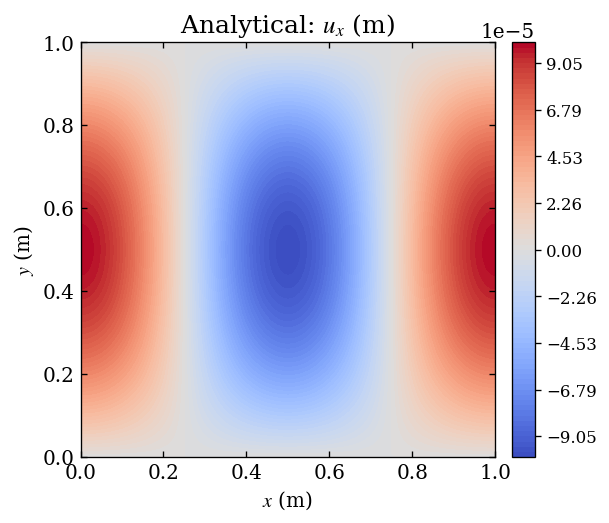

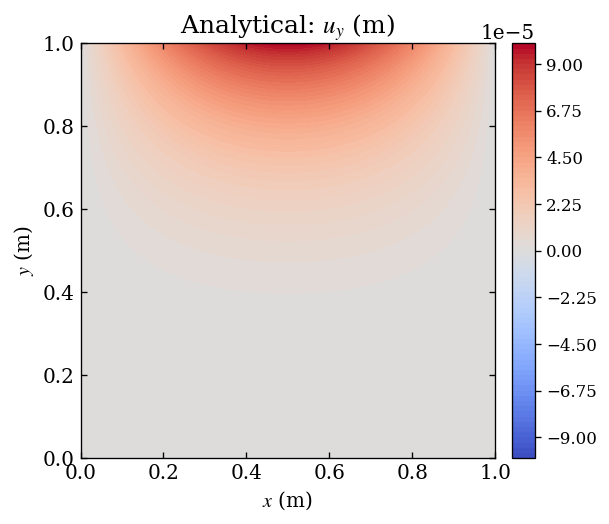

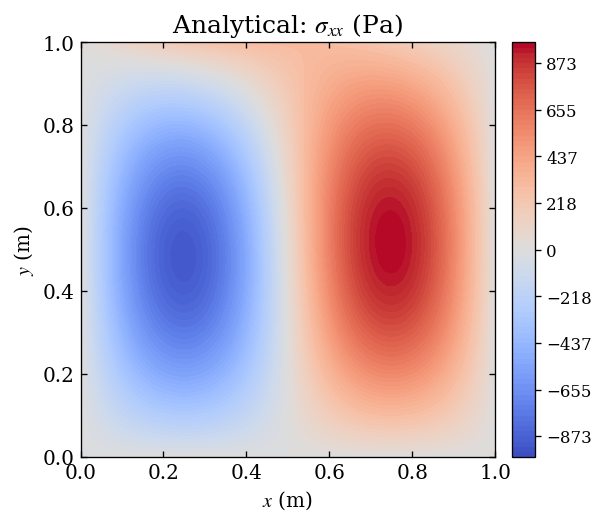

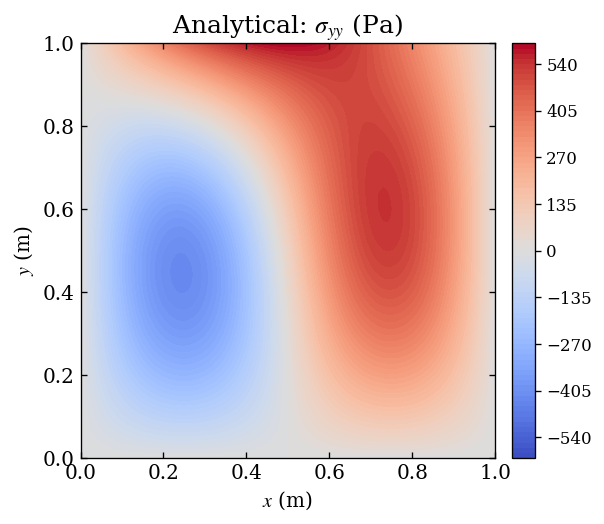

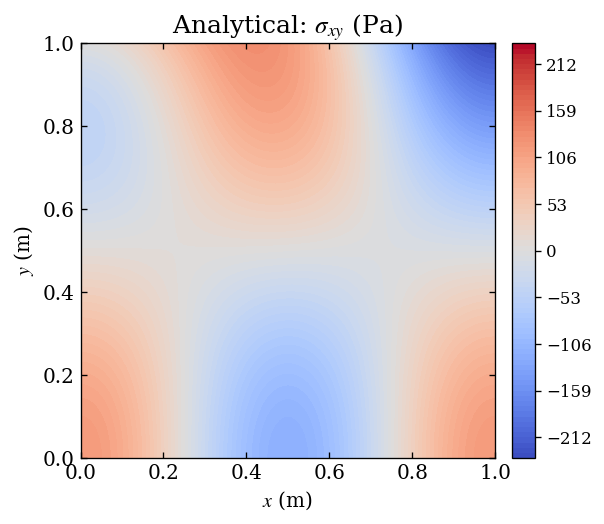

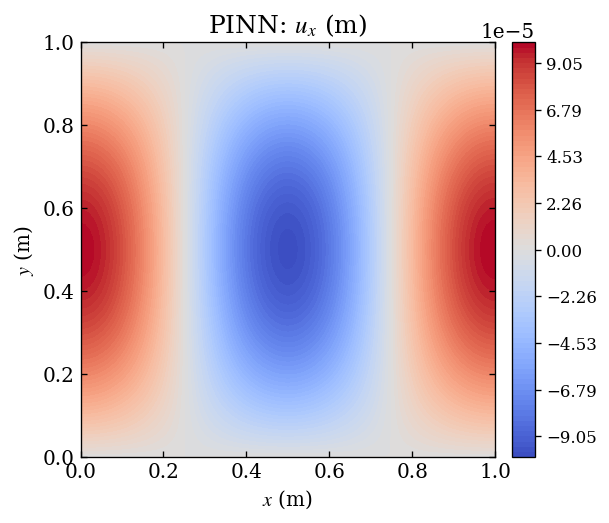

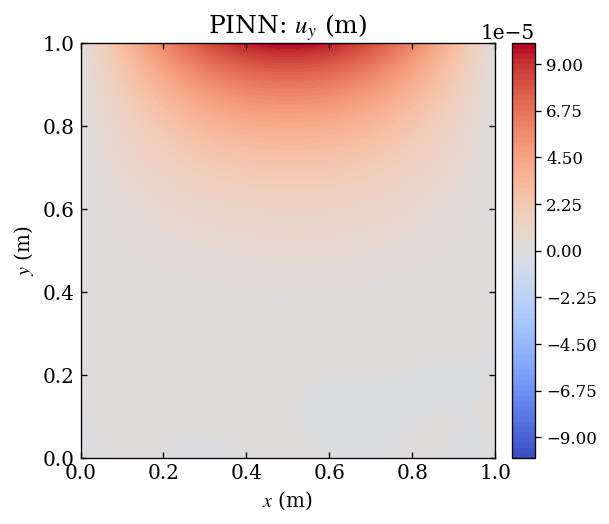

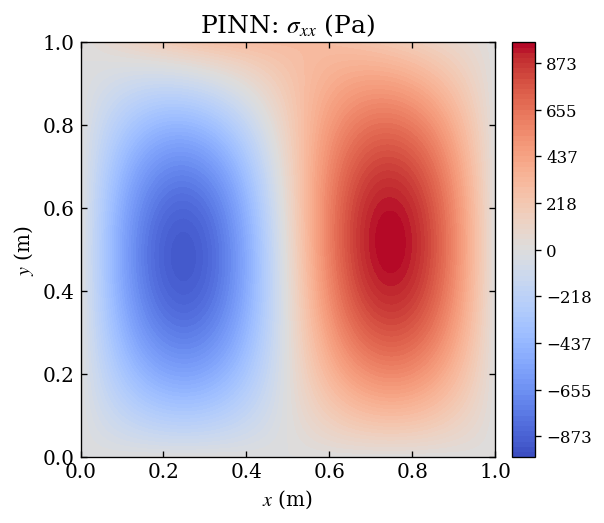

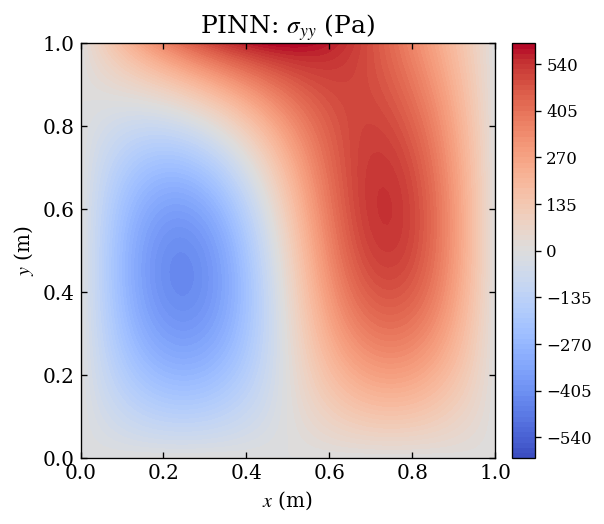

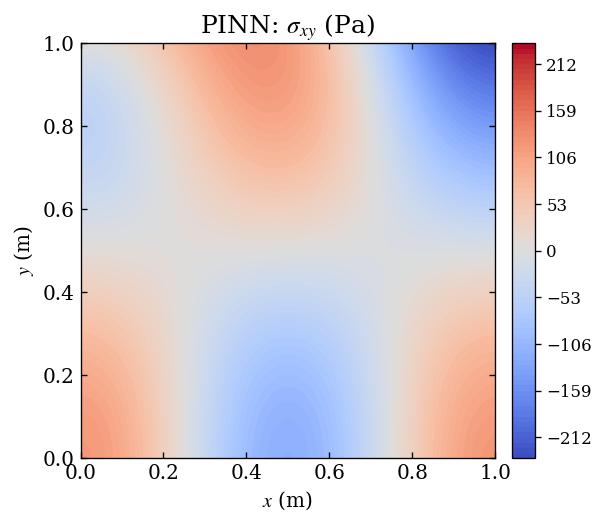

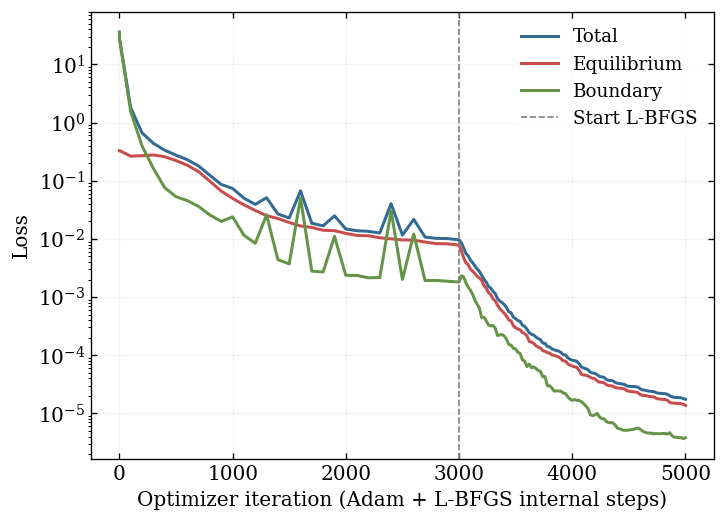

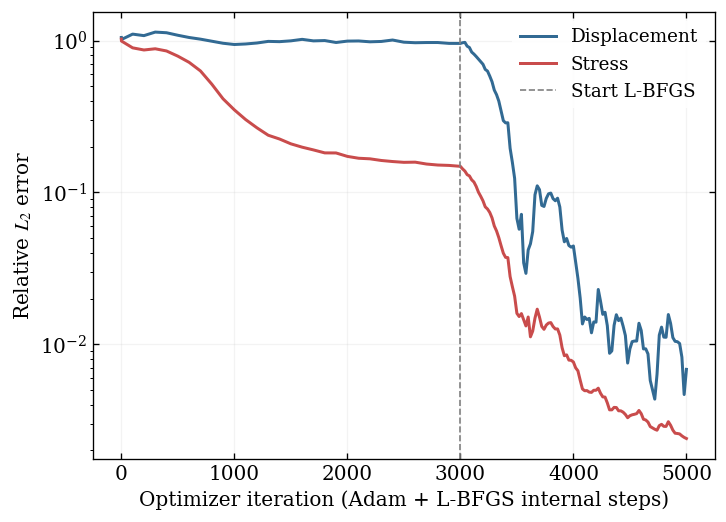

In [ ]:
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],
                     'mathtext.fontset':'stix','font.size':12})
folder=Path(cfg['output_dir'])
def savefig(fig,name):
    if cfg['save_outputs']:
        folder.mkdir(parents=True,exist_ok=True)
        fig.savefig(folder/name,dpi=300,bbox_inches='tight')

# Analytical and PINN figures use the same ranges; no percentile clipping.
for kind,values in [('Analytical',reference_real),('PINN',prediction_real)]:
    for i,(name,label) in enumerate(zip(quantities,labels)):
        vmax=max(float(np.max(abs(reference_real[:,i]))),float(np.max(abs(prediction_real[:,i]))),1e-16)
        fig,ax=plt.subplots(figsize=(5.4,4.8),dpi=150)
        fig.subplots_adjust(left=.16,right=.80,bottom=.14,top=.88)
        im=ax.contourf(L*X,L*Y,values[:,i].reshape(X.shape),levels=np.linspace(-vmax,vmax,81),cmap='coolwarm',extend='both')
        ax.set_aspect('equal',adjustable='box');ax.set_title(f'{kind}: {label}',fontsize=15)
        ax.set_xlabel(r'$x$ (m)');ax.set_ylabel(r'$y$ (m)');ax.tick_params(direction='in',top=True,right=True)
        cax=ax.inset_axes([1.04,0,.055,1]);cb=fig.colorbar(im,cax=cax,extendrect=True,extendfrac=0)
        cb.formatter.set_powerlimits((-3,3));cb.update_ticks();cb.ax.tick_params(labelsize=10)
        savefig(fig,f'{kind.lower()}_{name}.png');plt.show()

rows=[r for r in history if r['stage']!='Final']
steps=np.array([r['optimizer_steps'] for r in rows])
for keys,ylabel,filename in [(['total_loss','pde_loss','boundary_loss'],'Loss','loss_history.png'),
                              (['displacement_L2','stress_L2'],r'Relative $L_2$ error','error_history.png')]:
    fig,ax=plt.subplots(figsize=(6.2,4.5),dpi=150)
    for key,name,color in zip(keys,(['Total','Equilibrium','Boundary'] if len(keys)==3 else ['Displacement','Stress']),
                              ['#326A93','#C94C4C','#659347']):
        ax.semilogy(steps,[max(r[key],1e-30) for r in rows],label=name,lw=1.8,color=color)
    if cfg['adam_steps'] and cfg['lbfgs_epochs']:ax.axvline(cfg['adam_steps'],color='gray',ls='--',lw=1,label='Start L-BFGS')
    ax.set_xlabel('Optimizer iteration (Adam + L-BFGS internal steps)');ax.set_ylabel(ylabel)
    ax.tick_params(direction='in',top=True,right=True);ax.grid(alpha=.15)
    ax.legend(loc='best',fontsize=11,framealpha=.85,edgecolor='none');fig.tight_layout()
    savefig(fig,filename);plt.show()

if cfg['save_outputs']:
    folder.mkdir(parents=True,exist_ok=True)
    for filename,rows_out in [('field_errors.csv',error_table),('training_history.csv',history)]:
        with (folder/filename).open('w',newline='',encoding='utf-8-sig') as stream:
            writer=csv.DictWriter(stream,fieldnames=list(rows_out[0]));writer.writeheader();writer.writerows(rows_out)
    summary=dict(method='Displacement PINN',parameter_count=parameter_count,
                 n_interior=cfg['n_interior'],n_boundary=4*cfg['n_boundary_per_side'],
                 dtype='float64',device=str(device),solver_elapsed_seconds=solver_elapsed,
                 initialization_adam_seconds=adam_elapsed,lbfgs_seconds=lbfgs_elapsed,
                 pde_residual_scale=pde_scale,stress_scale_Pa=Sigma_ref,
                 best_training_loss=best_loss,settings=cfg)
    (folder/'run_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
    np.savez(folder/'fields_and_coefficients.npz',X=L*X,Y=L*Y,prediction=prediction_real,
             reference=reference_real,quantities=np.array(quantities),solver_elapsed_seconds=solver_elapsed)
    torch.save(model.state_dict(),folder/'pinn_state.pt')

# Optional direct comparison with the previous KM-PIKFNN exported grid.
km_file=Path(cfg['km_output_dir'])/'fields_and_coefficients.npz'
if km_file.is_file():
    with np.load(km_file) as kdata:
        if (np.array_equal(kdata['quantities'],np.array(quantities)) and
            kdata['X'].shape==X.shape and np.allclose(kdata['X'],L*X) and np.allclose(kdata['Y'],L*Y) and
            np.allclose(kdata['reference'],reference_real,rtol=1e-8,atol=1e-12)):
            km_pred=kdata['prediction'];comparison=[]
            print('\nSame-grid comparison: quantity | KM-PIKFNN L2 | PINN L2')
            for i,name in enumerate(quantities):
                err=np.linalg.norm(km_pred[:,i]-reference_real[:,i])/np.linalg.norm(reference_real[:,i])
                row=dict(quantity=name,KM_PIKFNN_L2=err,PINN_L2=error_table[i]['relative_L2']);comparison.append(row)
                print(f"{name:4s} | {err:.6e} | {row['PINN_L2']:.6e}")
            if cfg['save_outputs']:
                with (folder/'KM_vs_PINN_errors.csv').open('w',newline='',encoding='utf-8-sig') as stream:
                    writer=csv.DictWriter(stream,fieldnames=list(comparison[0]));writer.writeheader();writer.writerows(comparison)
        else:print('KM data differ in grid/material/scales/reference; automatic comparison skipped.')
else:print('To compare against KM, set cfg["km_output_dir"] to its saved-results directory.')
